# 최종 HGB 경보 시점 기준 결함 유형 분류기 재학습

기존 유형 분류기는 이전 Extra Trees 경보 시점을 기준으로 학습됐습니다. 이 노트북은 최적화 HGB의 `0.35 이상 2분 연속` 경보 시점으로 유형 특징을 다시 만들고 재학습합니다.

- 모델·집계시간 선택: Validation macro F1
- 동률: 더 짧은 집계시간, 그다음 accuracy
- Test: 선택 완료 후 한 번만 평가
- 비교 감사: 다단계 확정 경보 `0.45 이상 2분`에서도 결과 확인

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestCentroid
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib

warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',180);pd.set_option('display.max_columns',30);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})
ROOT=Path.cwd()
if not (ROOT/'data/modeling').exists(): ROOT=ROOT.parent
df=pd.read_csv(ROOT/'data/modeling/realtime_event_features.csv.gz').sort_values(['sample_event_id','relative_min']).reset_index(drop=True)
config=json.loads((ROOT/'models/binary_fault_detector_optimized_config.json').read_text())
binary_model=joblib.load(ROOT/'models/binary_fault_detector_hgb_optimized.joblib')
feature_cols=config['feature_columns']
print(f'행 {len(df):,}, 결함 이벤트 {df.loc[df.is_fault.eq(1),"sample_event_id"].nunique()}개, HGB 입력 {len(feature_cols)}개')

행 59,991, 결함 이벤트 35개, HGB 입력 176개


## 1. HGB 특징과 유형 진단 특징 재생성

직전 6시간 평균·표준편차는 현재값을 제외하고 계산합니다. Train 중앙값만 사용해 남은 결측을 채웁니다.

In [2]:
sensor_cols=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
grouped=df.groupby('sample_event_id',sort=False);parts=[];z_cols=[]
for col in sensor_cols:
    mean_6h=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean())
    std_6h=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan)
    a=f'{col}__z_6h';b=f'{col}__mean15_vs_6h';z_cols.extend([a,b])
    parts.append(pd.DataFrame({a:((df[col]-mean_6h)/std_6h).clip(-20,20).astype('float32'),b:((df[f'{col}__mean_15m']-mean_6h)/std_6h).clip(-20,20).astype('float32')}))
df=pd.concat([df,pd.concat(parts,axis=1)],axis=1)
train_medians=df.loc[df.split.eq('train'),feature_cols].median();df[feature_cols]=df[feature_cols].fillna(train_medians)
df['binary_probability']=binary_model.predict_proba(df[feature_cols])[:,1]
print('추가 기준선 특징:',len(z_cols),'HGB 확률 범위:',df.binary_probability.min(),df.binary_probability.max())

추가 기준선 특징: 24 HGB 확률 범위: 1.5243912706075146e-05 0.9999847516049973


## 2. 최적화 HGB와 확정 경보 시점

각 결함 이벤트에서 임계값이 연속 조건을 처음 만족한 시점을 경보 시점으로 사용합니다.

In [3]:
def event_alerts(threshold,persistence):
    rows=[]
    for event_id,g in df[df.sample_kind.eq('post_fault')].groupby('sample_event_id'):
        g=g.sort_values('relative_min');hit=g.binary_probability.ge(threshold).to_numpy()
        sustained=np.convolve(hit,np.ones(persistence,dtype=int),mode='valid')==persistence
        indices=np.flatnonzero(sustained)+persistence-1
        rows.append({'sample_event_id':event_id,'alert_min':float(g.iloc[indices[0]].relative_min) if len(indices) else np.nan})
    return pd.DataFrame(rows)

policies={'optimized_hgb':(.35,2),'confirmed_stage':(.45,2)}
alert_maps={name:event_alerts(*rule) for name,rule in policies.items()}
for name,alerts in alert_maps.items():
    print(name,'미탐',alerts.alert_min.isna().sum(),'중앙 지연',alerts.alert_min.median())

optimized_hgb 미탐 0 중앙 지연 1.0
confirmed_stage 미탐 0 중앙 지연 1.0


## 3. 경보 이후 0·15·30·60분 유형 특징

12개 센서의 두 기준선 특징에 대해 평균과 절댓값 최대치를 계산해 이벤트당 48개 특징을 만듭니다.

In [4]:
def build_event_features(alerts,horizon):
    alert_map=alerts.set_index('sample_event_id').alert_min.to_dict();rows=[]
    for event_id,g in df[df.sample_kind.eq('post_fault')].groupby('sample_event_id'):
        alert=float(alert_map[event_id]);window=g[g.relative_min.between(alert,alert+horizon)]
        row={'sample_event_id':event_id,'split':g.split.iloc[0],'operating_regime':g.operating_regime.iloc[0],'fault_type':int(g.fault_type.iloc[0]),'alert_min':alert,'aggregation_min':horizon,'decision_min':alert+horizon}
        for col in z_cols:
            row[f'{col}__mean']=window[col].mean();row[f'{col}__maxabs']=window[col].abs().max()
        rows.append(row)
    return pd.DataFrame(rows).fillna(0)

def compare_policy(policy_name):
    candidate_rows=[];objects={}
    for horizon in [0,15,30,60]:
        event_data=build_event_features(alert_maps[policy_name],horizon)
        event_features=[x for x in event_data if x.endswith('__mean') or x.endswith('__maxabs')]
        train=event_data.split.eq('train');validation=event_data.split.eq('validation')
        models={
          'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(C=.2,class_weight='balanced',max_iter=1000,random_state=42)),
          'Nearest centroid':make_pipeline(StandardScaler(),NearestCentroid()),
          'Extra Trees':ExtraTreesClassifier(n_estimators=500,max_depth=4,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42),
        }
        for name,model in models.items():
            model.fit(event_data.loc[train,event_features],event_data.loc[train,'fault_type'])
            pred=model.predict(event_data.loc[validation,event_features])
            candidate_rows.append({'policy':policy_name,'horizon_min':horizon,'model':name,'validation_accuracy':accuracy_score(event_data.loc[validation,'fault_type'],pred),'validation_macro_f1':f1_score(event_data.loc[validation,'fault_type'],pred,average='macro')})
            objects[(horizon,name)]=(model,event_data,event_features)
    comparison=pd.DataFrame(candidate_rows).sort_values(['validation_macro_f1','horizon_min','validation_accuracy'],ascending=[False,True,False])
    best=comparison.iloc[0];return comparison,best,objects[(int(best.horizon_min),str(best.model))]

comparison,best,(selected_model,event_data,event_feature_cols)=compare_policy('optimized_hgb')
print(comparison.to_string(index=False));print('\n선택:',best.to_dict())

       policy  horizon_min               model  validation_accuracy  validation_macro_f1
optimized_hgb           30 Logistic regression                0.875                0.867
optimized_hgb           30    Nearest centroid                0.875                0.867
optimized_hgb           60 Logistic regression                0.875                0.867
optimized_hgb           60    Nearest centroid                0.875                0.867
optimized_hgb           30         Extra Trees                0.750                0.667
optimized_hgb           60         Extra Trees                0.750                0.667
optimized_hgb           15 Logistic regression                0.625                0.600
optimized_hgb           15    Nearest centroid                0.625                0.600
optimized_hgb           15         Extra Trees                0.500                0.500
optimized_hgb            0         Extra Trees                0.125                0.062
optimized_hgb        

Validation에서 30분과 60분 Logistic Regression의 macro F1이 0.867로 같았습니다. 동률일 때 더 빠른 진단을 우선해 30분 모델을 선택했습니다.

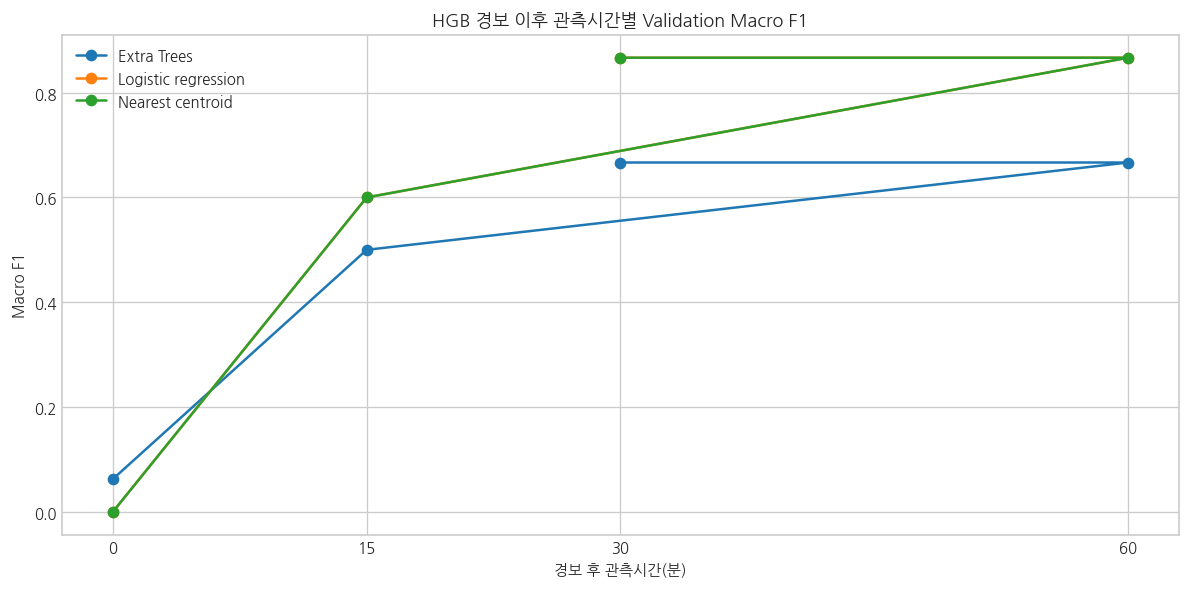

In [5]:
fig,ax=plt.subplots(figsize=(10,5))
for name,g in comparison.groupby('model'):ax.plot(g.horizon_min,g.validation_macro_f1,marker='o',label=name)
ax.set(title='HGB 경보 이후 관측시간별 Validation Macro F1',xlabel='경보 후 관측시간(분)',ylabel='Macro F1',xticks=[0,15,30,60]);ax.legend();plt.tight_layout();plt.show()

## 4. 고정된 30분 모델의 Test 검증

              precision    recall  f1-score   support

           1      0.500     0.500     0.500         2
           2      1.000     1.000     1.000         2
           3      0.500     0.500     0.500         2
           4      1.000     1.000     1.000         2

    accuracy                          0.750         8
   macro avg      0.750     0.750     0.750         8
weighted avg      0.750     0.750     0.750         8

 sample_event_id operating_regime  fault_type  predicted_fault_type  confidence  alert_min  decision_min
              23                B           3                     3       0.797     27.000        57.000
              28                B           2                     2       0.919     36.000        66.000
              29                B           4                     4       0.832     16.000        46.000
              31                B           1                     1       0.675     33.000        63.000
              32                A       

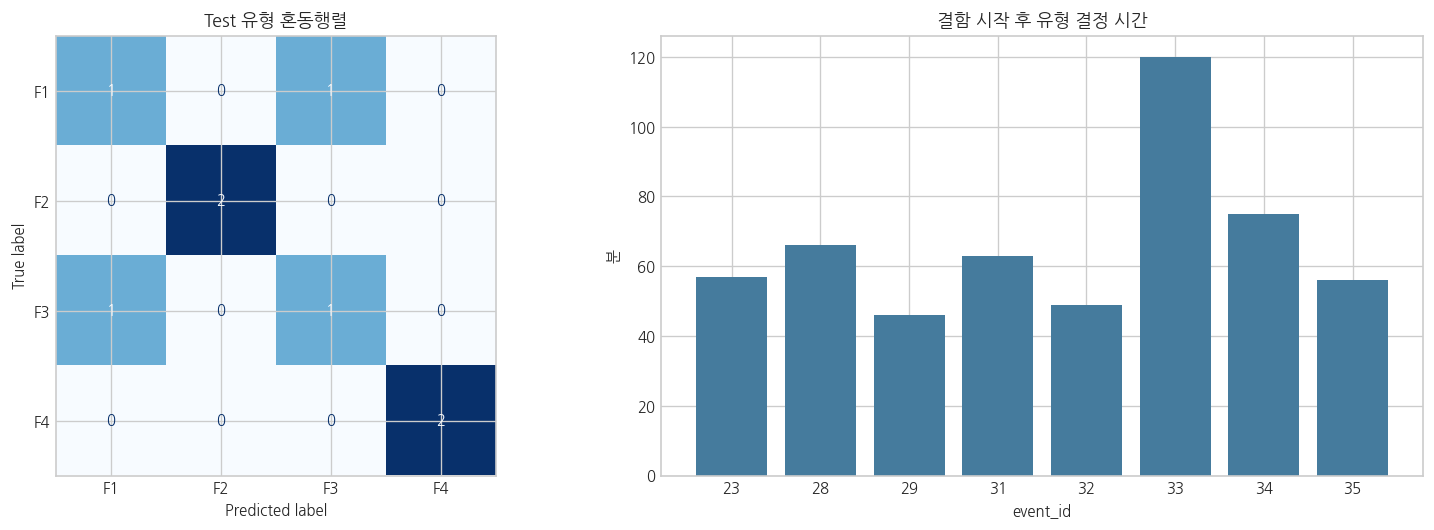

In [6]:
test=event_data[event_data.split.eq('test')].copy();test['predicted_fault_type']=selected_model.predict(test[event_feature_cols]);probability=selected_model.predict_proba(test[event_feature_cols]);test['confidence']=probability.max(axis=1)
test_accuracy=accuracy_score(test.fault_type,test.predicted_fault_type);test_macro_f1=f1_score(test.fault_type,test.predicted_fault_type,average='macro')
print(classification_report(test.fault_type,test.predicted_fault_type,digits=3))
print(test[['sample_event_id','operating_regime','fault_type','predicted_fault_type','confidence','alert_min','decision_min']].to_string(index=False))
print(f'\nTest accuracy={test_accuracy:.3f}, macro F1={test_macro_f1:.3f}, 중앙 유형 확정={test.decision_min.median():.1f}분')
fig,axes=plt.subplots(1,2,figsize=(13,4.5));ConfusionMatrixDisplay(confusion_matrix(test.fault_type,test.predicted_fault_type,labels=[1,2,3,4]),display_labels=['F1','F2','F3','F4']).plot(ax=axes[0],cmap='Blues',colorbar=False);axes[0].set_title('Test 유형 혼동행렬');axes[1].bar(test.sample_event_id.astype(str),test.decision_min,color='#457b9d');axes[1].set(title='결함 시작 후 유형 결정 시간',xlabel='event_id',ylabel='분');plt.tight_layout();plt.show()

Test에서는 8개 중 6개를 맞혔습니다. F1 한 건을 F3로, F3 한 건을 F1로 분류해 냉각 성능 저하와 센서 드리프트의 온도 상승 패턴이 실제 혼동 지점임을 확인했습니다. 유형 결정 중앙 시간은 결함 시작 후 60분입니다.

## 5. 다단계 확정 경보 시점 감사

웹에서 확정 경보 0.45·2분을 기준으로 사용할 가능성이 있어 같은 절차를 반복합니다. Test를 보고 설정을 바꾸지 않습니다.

In [7]:
confirmed_comparison,confirmed_best,(confirmed_model,confirmed_data,confirmed_features)=compare_policy('confirmed_stage')
confirmed_test=confirmed_data[confirmed_data.split.eq('test')].copy();confirmed_test['predicted']=confirmed_model.predict(confirmed_test[confirmed_features])
print('Validation 선택:',confirmed_best.to_dict())
print('Test accuracy:',accuracy_score(confirmed_test.fault_type,confirmed_test.predicted))
print('Test macro F1:',f1_score(confirmed_test.fault_type,confirmed_test.predicted,average='macro'))
print('Test 중앙 유형 확정:',confirmed_test.decision_min.median(),'분')

Validation 선택: {'policy': 'confirmed_stage', 'horizon_min': 30, 'model': 'Logistic regression', 'validation_accuracy': 0.875, 'validation_macro_f1': 0.8666666666666667}
Test accuracy: 0.75
Test macro F1: 0.75
Test 중앙 유형 확정: 62.0 분


확정 경보 기준에서도 30분 Logistic Regression이 선택됐고 Test accuracy와 macro F1은 0.75였습니다. 따라서 유형 분류 성능은 두 HGB 경보 정책에서 동일했으며, 더 빠른 optimized HGB 경보 기준 모델을 저장합니다.

## 6. 모델과 결과 저장

In [8]:
model_path=ROOT/'models/fault_type_classifier_hgb_alert_logistic.joblib';config_path=ROOT/'models/fault_type_classifier_hgb_alert_config.json';features_path=ROOT/'data/modeling/fault_type_hgb_alert_event_features.csv';prediction_path=ROOT/'data/modeling/test_fault_type_hgb_alert_predictions.csv'
joblib.dump(selected_model,model_path);event_data.to_csv(features_path,index=False);test.to_csv(prediction_path,index=False)
new_config={'target':'fault_type','classes':{'1':'Cooling System Degradation','2':'Feed Flow Blockage','3':'Sensor Drift','4':'Mechanical Wear'},'binary_model':'models/binary_fault_detector_hgb_optimized.joblib','binary_alert_threshold':.35,'binary_alert_persistence_minutes':2,'aggregation_minutes':int(best.horizon_min),'model':str(best.model),'input_feature_columns':event_feature_cols,'validation_accuracy':float(best.validation_accuracy),'validation_macro_f1':float(best.validation_macro_f1),'test_accuracy':float(test_accuracy),'test_macro_f1':float(test_macro_f1),'test_median_alert_min':float(test.alert_min.median()),'test_median_decision_min':float(test.decision_min.median()),'test_confusions':['F1 predicted as F3: 1 event','F3 predicted as F1: 1 event'],'limitations':['Only 19 train, 8 validation, and 8 test events.','Only two test events per fault type.','Test was not used for model or horizon selection.']}
config_path.write_text(json.dumps(new_config,ensure_ascii=False,indent=2),encoding='utf-8')
print(model_path);print(config_path);print(features_path);print(prediction_path)

/Users/hyemi/green-pulse-ai/models/fault_type_classifier_hgb_alert_logistic.joblib
/Users/hyemi/green-pulse-ai/models/fault_type_classifier_hgb_alert_config.json
/Users/hyemi/green-pulse-ai/data/modeling/fault_type_hgb_alert_event_features.csv
/Users/hyemi/green-pulse-ai/data/modeling/test_fault_type_hgb_alert_predictions.csv


## 7. 결론

- 최종 HGB 경보 시점에 맞춰 유형 분류기를 재학습했습니다.
- 60분과 동일한 Validation macro F1을 얻은 30분 Logistic Regression을 선택했습니다.
- Test accuracy와 macro F1은 0.75이며 F1과 F3가 한 건씩 혼동됐습니다.
- Test 중앙 이진 경보는 30분, 중앙 유형 결정은 결함 시작 후 60분입니다.
- 기존 유형 모델의 Test 100%는 이전 경보 시점에 종속된 결과였으며 새 파이프라인의 성능으로 사용하지 않습니다.
- 웹 연동에는 새 HGB 정렬 모델을 사용하되, 이벤트가 35개뿐이므로 prototype 상태를 유지합니다.